Dataset Shape: (4998, 141)
        0         1         2         3         4         5         6    \
0 -0.112522 -2.827204 -3.773897 -4.349751 -4.376041 -3.474986 -2.181408   
1 -1.100878 -3.996840 -4.285843 -4.506579 -4.022377 -3.234368 -1.566126   
2 -0.567088 -2.593450 -3.874230 -4.584095 -4.187449 -3.151462 -1.742940   
3  0.490473 -1.914407 -3.616364 -4.318823 -4.268016 -3.881110 -2.993280   
4  0.800232 -0.874252 -2.384761 -3.973292 -4.338224 -3.802422 -2.534510   

        7         8         9    ...       131       132       133       134  \
0 -1.818286 -1.250522 -0.477492  ...  0.792168  0.933541  0.796958  0.578621   
1 -0.992258 -0.754680  0.042321  ...  0.538356  0.656881  0.787490  0.724046   
2 -1.490659 -1.183580 -0.394229  ...  0.886073  0.531452  0.311377 -0.021919   
3 -1.671131 -1.333884 -0.965629  ...  0.350816  0.499111  0.600345  0.842069   
4 -1.783423 -1.594450 -0.753199  ...  1.148884  0.958434  1.059025  1.371682   

        135       136       137       138

Model: "auto_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 8)                   │          11,768 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential_1 (Sequential)            │ (None, 140)                 │          11,900 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 71,006 (277.37 KB)

 Trainable params: 23,668 (92.45 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 47,338 (184.92 KB)

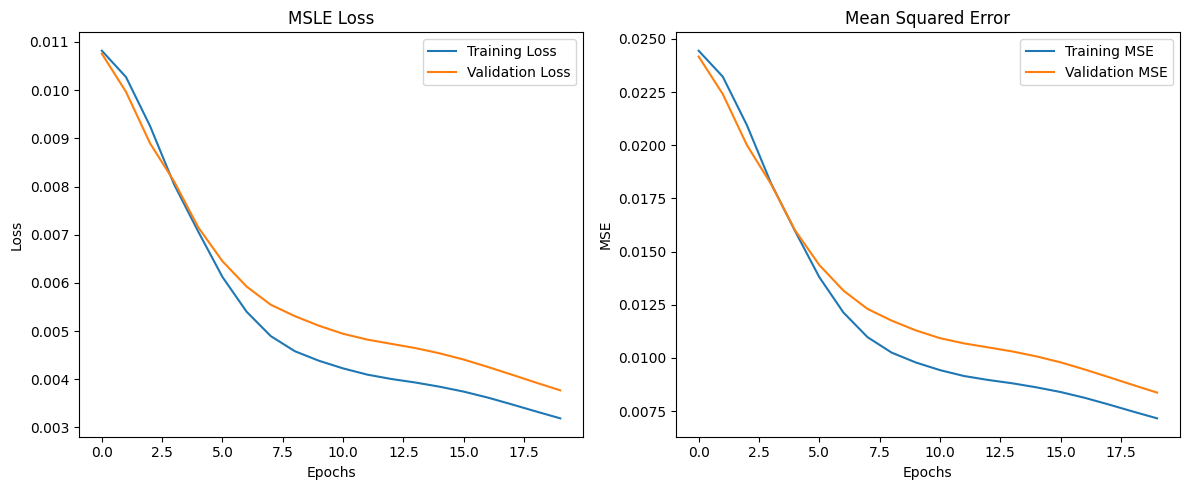

73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

Anomaly Threshold: 0.007908966
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

Model Accuracy: 95.3 %

Actual Labels:     [0 0 1 1 1 1 0 0 0 1]
Predicted Labels:  [0 0 0 1 0 1 0 0 0 1]

Normal Samples Predicted: 545
Abnormal Samples Predicted: 455


In [1]:

# EXPERIMENT 4: ECG ANOMALY DETECTION USING AUTOENCODER

# 1. Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score

from tensorflow.keras import Model, Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import MeanSquaredLogarithmicError

# 2. Set random seed
np.random.seed(42)
tf.random.set_seed(42)

# 3. Load ECG dataset
url = "https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv"

data = pd.read_csv(url, header=None)

print("Dataset Shape:", data.shape)
print(data.head())

# 4. Separate features and target
features = data.iloc[:, :-1].values
target = data.iloc[:, -1].values.astype(int)

print("Features Shape:", features.shape)
print("Target Shape:", target.shape)

# 5. Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.2,
    random_state=42,
    stratify=target
)

# 6. Select only normal ECG data for training
# Target 1 = Normal
X_train_normal = X_train[y_train == 1]

print("Normal Training Data:", X_train_normal.shape)

# 7. Normalize data using MinMaxScaler
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train_normal)
X_test_scaled = scaler.transform(X_test)

print("Scaled Training Data:", X_train_scaled.shape)
print("Scaled Testing Data:", X_test_scaled.shape)

# 8. Create Autoencoder Model
class AutoEncoder(Model):

    def __init__(self, output_units):
        super(AutoEncoder, self).__init__()

        # Encoder: 4 Dense layers
        self.encoder = Sequential([
            Dense(64, activation='relu'),
            Dropout(0.2),
            Dense(32, activation='relu'),
            Dropout(0.2),
            Dense(16, activation='relu'),
            Dense(8, activation='relu')
        ])

        # Decoder: 4 Dense layers
        self.decoder = Sequential([
            Dense(16, activation='relu'),
            Dense(32, activation='relu'),
            Dense(64, activation='relu'),
            Dense(output_units, activation='sigmoid')
        ])

    def call(self, inputs):
        encoded = self.encoder(inputs)
        decoded = self.decoder(encoded)
        return decoded


# 9. Create Autoencoder object
model = AutoEncoder(output_units=X_train_scaled.shape[1])

# 10. Compile the model
model.compile(
    optimizer=Adam(),
    loss=MeanSquaredLogarithmicError(),
    metrics=['mse']
)

# 11. Train the model using normal ECG data
history = model.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=20,
    batch_size=512,
    validation_split=0.1,
    shuffle=True
)

# 12. Display model architecture
model.summary()

# 13. Plot training and validation loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('MSLE Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# 14. Plot MSE
plt.subplot(1, 2, 2)
plt.plot(history.history['mse'], label='Training MSE')
plt.plot(history.history['val_mse'], label='Validation MSE')
plt.title('Mean Squared Error')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.legend()

plt.tight_layout()
plt.show()

# 15. Calculate reconstruction errors on normal training data
train_predictions = model.predict(X_train_scaled)

train_errors = tf.keras.losses.msle(
    X_train_scaled,
    train_predictions
).numpy()

# 16. Calculate anomaly threshold
threshold = np.mean(train_errors) + np.std(train_errors)

print("\nAnomaly Threshold:", threshold)

# 17. Predict test data
test_predictions = model.predict(X_test_scaled)

# Calculate reconstruction errors
test_errors = tf.keras.losses.msle(
    X_test_scaled,
    test_predictions
).numpy()

# 18. Classify normal and abnormal samples
# Error > Threshold = Abnormal (0)
# Error <= Threshold = Normal (1)

y_pred = np.where(test_errors > threshold, 0, 1)

# 19. Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", accuracy * 100, "%")

# 20. Display prediction results
print("\nActual Labels:    ", y_test[:10])
print("Predicted Labels: ", y_pred[:10])

# 21. Display normal and abnormal counts
print("\nNormal Samples Predicted:", np.sum(y_pred == 1))
print("Abnormal Samples Predicted:", np.sum(y_pred == 0))
